[GitHub repository: Jingyi-Jia/stat-37711-ml](https://github.com/Jingyi-Jia/stat-37711-ml)

# Problem 1: Betting on the 2020 election

Let $d>0$ be Victor's wealth and $b\in[0,d]$ his bet on Biden. At a market price of $0.6$, each dollar bet earns a net profit of $(1-0.6)/0.6=2/3$ if Biden wins and is lost otherwise.

## (a) Linear utility

Victor assigns probability $0.85$ to a Biden victory. With $U(y)=y$, his expected utility from final wealth $W(b)$ is

$$
\mathbb E[U(W(b))]
=0.85\left(d+\frac23 b\right)+0.15(d-b)
=d+\frac{5}{12}b.
$$

This increases with $b$, so he bets his entire wealth: $b^*=d$.

Linear utility makes Victor risk-neutral. It may be reasonable for small bets, but here it leads him to accept a 15% chance of losing everything. Concave utility better captures the importance of keeping some savings.

## (b) Logarithmic utility

With $U(y)=\log y$, expected utility for $0\le b<d$ is

$$
E(b)=0.85\log\left(d+\frac23 b\right)+0.15\log(d-b).
$$

Setting the derivative equal to zero gives

$$
\begin{aligned}
E'(b)&=\frac{0.85(2/3)}{d+(2/3)b}-\frac{0.15}{d-b}=0,\\
\frac{17}{30}(d-b)&=\frac{3}{20}\left(d+\frac23 b\right),\\
34d-34b&=9d+6b.
\end{aligned}
$$

Thus $b^*=5d/8=0.625d$. Since $E(b)$ is strictly concave, this interior critical point is the unique maximum.


## (c) Would I make this bet with a net worth of \$500,000?

No. The bet would be \$312,500, leaving \$187,500 if Biden loses. A 15% chance of losing 62.5% of my wealth is more risk than I would accept. Even if I agreed with Victor's probability, I would make a much smaller bet and keep the rest of my savings available for other needs.


# Problem 2: Cross-entropy is a proper scoring rule

For binary $Y$, let $\eta(x)=P(Y=1\mid X=x)$ and let $f(x)\in[0,1]$ be a measurable probability prediction. The cross-entropy loss is

$$
L(y,u)=-y\log u-(1-y)\log(1-u),
$$

with $0\log0=0$ and infinite loss for a probability-zero prediction of an event that occurs.

Fix $x$ and write $\eta=\eta(x)$ and $u=f(x)$. The conditional expected loss is

$$
R_x(u)=-\eta\log u-(1-\eta)\log(1-u).
$$

For $0<\eta,u<1$, subtracting the conditional expected loss at the true probability and using $-\log t\ge 1-t$ gives

$$
\begin{aligned}
R_x(u)-R_x(\eta)
&=\eta\log\frac{\eta}{u}+(1-\eta)\log\frac{1-\eta}{1-u}\\
&\ge\eta\left(1-\frac{u}{\eta}\right)
 +(1-\eta)\left(1-\frac{1-u}{1-\eta}\right)=0.
\end{aligned}
$$

Equality holds only at $u=\eta$. If $0<\eta<1$ and $u\in\{0,1\}$, the loss is infinite. If $\eta=0$, then $R_x(u)=-\log(1-u)$ is minimized at $u=0$. If $\eta=1$, then $R_x(u)=-\log u$ is minimized at $u=1$.

Thus the true probability uniquely minimizes the conditional expected loss at each $x$. Taking expectations over $X$,

$$
\begin{aligned}
\mathbb E[L(Y,f(X))]
&=\mathbb E[R_X(f(X))]\\
&\ge\mathbb E[R_X(\eta(X))]
=\mathbb E[L(Y,\eta(X))].
\end{aligned}
$$

Since $R_x(\eta(x))\le\log2$, the risk at the true probability is finite. Equality therefore requires $f(X)=\eta(X)$ almost surely. Hence $f^*(x)=P(Y=1\mid X=x)$ minimizes the risk, so cross-entropy is strictly proper.


# Problem 3: Constant step sizes in SGD

The condition $\sum_t\rho_t^2<\infty$ is used to obtain exact asymptotic convergence with persistent gradient noise. A constant step size can still be reasonable for finite-sample prediction.

Let $F(\theta)$ be the empirical loss and $\hat\theta$ its minimizer. Suppose $F$ is $\mu$-strongly convex with an $L$-Lipschitz gradient, and the stochastic gradients are unbiased with noise variance at most $\sigma^2$. For a constant step $0<\rho\le 1/L$, a standard bound is

$$
\begin{aligned}
\mathbb E[F(\theta_t)-F(\hat\theta)]
&\le (1-\mu\rho)^t\bigl[F(\theta_0)-F(\hat\theta)\bigr]
+\frac{L\rho\sigma^2}{2\mu}.
\end{aligned}
$$

The first term decreases geometrically, leaving an $O(\rho)$ bound on expected excess loss. If the empirical-to-population loss error is $O(n^{-1/2})$, we can choose $\rho$ so that this optimization error is smaller than the statistical error. For example, $\rho=o(n^{-1/2})$ makes the remaining optimization error negligible once the first term has decayed. The step is constant across iterations for each fixed sample size. Here $O(\rho)$ measures excess loss. The corresponding root mean squared distance from $\hat\theta$ is $O(\sqrt{\rho})$.

A second reason applies under interpolation, when every individual training loss has the same minimizer. For squared-error loss, this occurs when the model fits every training observation exactly. Then

$$
\nabla\ell_i(\hat\theta)=0\qquad\text{for every }i,
$$

so the gradient noise vanishes at the empirical minimizer. With smooth convex individual losses and a strongly convex average, a sufficiently small constant step gives exact convergence in mean square. There is no persistent noise to prevent convergence.

In practice, we also stop after a finite number of iterations. A constant step avoids shrinking updates too early; the step size and stopping point can be chosen using validation data.

# Problem 4: Residual normality in the ALE dataset

I predict `ale` from the first four columns of the [ALE dataset](https://doi.org/10.24432/C5ZP6R): `anchor_ratio`, `trans_range`, `node_density`, and `iterations`. I fit five regression models to its 107 observations, standardizing the predictors for support vector regression and the neural network.

I use five-fold cross-validation to obtain residuals $r_i=y_i-\hat y_i$, with each prediction made by a model fitted without that observation. I check normality using D'Agostino-Pearson and Shapiro-Wilk tests at the 5% level, together with normal Q-Q plots. Since the fitted models share training data, I treat the test results as approximate diagnostics.

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import stats

torch.set_default_dtype(torch.float64)

In [2]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

ale = pd.read_csv("data/mcs_ds_edited_iter_shuffled.csv")
features = list(ale.columns[:4])
X_ale = ale[features].to_numpy(dtype=float)
y_ale = ale["ale"].to_numpy(dtype=float)
print("shape:", ale.shape, "| features:", features)

shape: (107, 6) | features: ['anchor_ratio', 'trans_range', 'node_density', 'iterations']


In [3]:
SEED = 37711
models = {
    "Linear regression": LinearRegression(),
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR(C=5, epsilon=0.1)),
    "Decision tree": DecisionTreeRegressor(max_depth=3, random_state=SEED),
    "Random forest": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=SEED),
    "Neural net (MLP)": make_pipeline(
        StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(64, 32), max_iter=5000, random_state=SEED)),
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

oof_residuals, rows = {}, []
for name, model in models.items():
    r = y_ale - cross_val_predict(model, X_ale, y_ale, cv=cv)
    oof_residuals[name] = r
    rows.append({
        "model": name,
        "RMSE": np.sqrt(np.mean(r ** 2)),
        "D'Agostino-Pearson p": stats.normaltest(r).pvalue,
        "Shapiro-Wilk p": stats.shapiro(r).pvalue,
    })

p4_results = pd.DataFrame(rows).set_index("model")
p4_table = p4_results.copy()
p4_table["RMSE"] = p4_table["RMSE"].map("{:.3f}".format)
for col in ["D'Agostino-Pearson p", "Shapiro-Wilk p"]:
    p4_table[col] = p4_table[col].map("{:.1e}".format)
p4_table

,RMSE,D'Agostino-Pearson p,Shapiro-Wilk p
model,,,
Linear regression,0.246,1.5e-09,6.1e-06
SVR (RBF),0.222,1.0e-05,7.2e-05
Decision tree,0.266,5.1e-06,1.3e-04
Random forest,0.211,3.6e-08,5.9e-05
Neural net (MLP),0.230,3.9e-08,1.6e-06


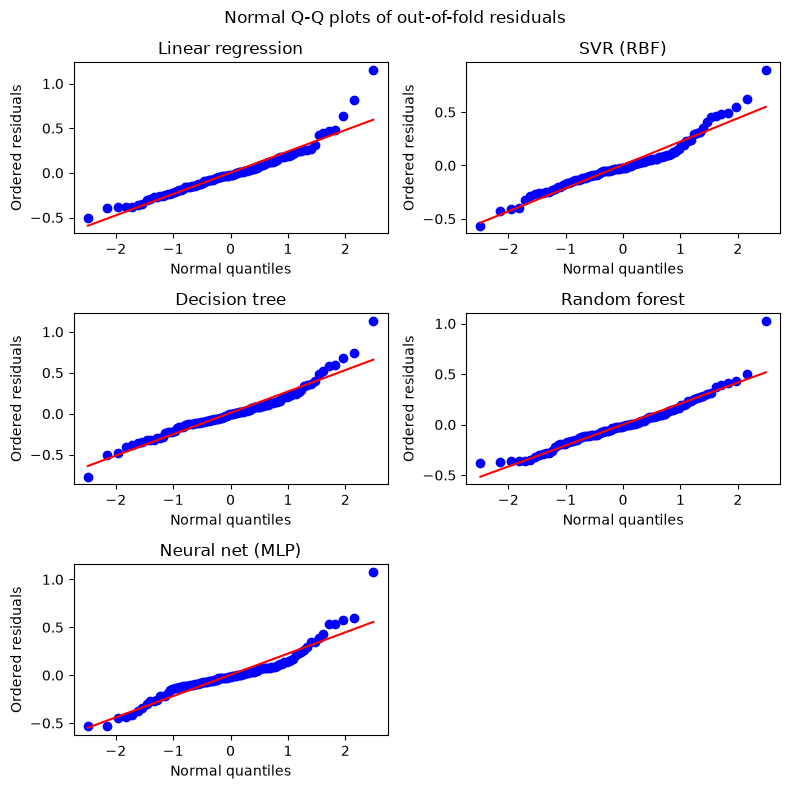

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(8, 8))
for ax, (name, r) in zip(axes.flat, oof_residuals.items()):
    stats.probplot(r, dist="norm", plot=ax)
    ax.set_title(name)
    ax.set_xlabel("Normal quantiles")
    ax.set_ylabel("Ordered residuals")
axes.flat[-1].axis("off")
fig.suptitle("Normal Q-Q plots of out-of-fold residuals")
fig.tight_layout()
plt.show()

Both tests give $p<0.001$ for all five models. The Q-Q plots show a long right tail, so normality is a poor approximation for these prediction errors. The random forest has the lowest RMSE, 0.211, compared with 0.246 for linear regression, but its residuals also depart from normality.

These results weaken the normal-error justification for squared-error loss. Squared-error loss can still be used to estimate the conditional mean without assuming normal errors.

# Problem 5: Custom losses with automatic differentiation

I use PyTorch to define the models and losses. The following loop trains each model with mini-batch SGD. `loss.backward()` computes the gradients, and `torch.optim.SGD` updates the weights and intercept.

In [5]:
def train_sgd(predict, loss_fn, X, y, *, lr, epochs, batch_size, seed=0):
    gen = torch.Generator().manual_seed(seed)
    n, d = X.shape
    w = torch.zeros(d, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    opt = torch.optim.SGD([w, b], lr=lr)
    history = []
    for epoch in range(epochs):
        perm = torch.randperm(n, generator=gen)
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            loss = loss_fn(predict(X[idx], w, b), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        with torch.no_grad():
            history.append(loss_fn(predict(X, w, b), y).item())
    return w.detach(), b.detach(), np.array(history)


def plot_history(histories, title):
    fig, ax = plt.subplots(figsize=(5, 3.2))
    for label, h in histories.items():
        ax.plot(np.arange(1, len(h) + 1), h, label=label)
    ax.set_xlabel("epoch"); ax.set_ylabel("training loss"); ax.set_title(title); ax.legend()
    fig.tight_layout(); plt.show()

## Classification: Breast Cancer Wisconsin

I use a stratified 80/20 split, giving 455 training observations and 114 test observations. All three classifiers use the same split and a feature scaler fitted on the training data. The baseline is scikit-learn's `LogisticRegression`.

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X_bc, y_bc = load_breast_cancer(return_X_y=True)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_bc, y_bc, test_size=0.2, random_state=42, stratify=y_bc)
scaler_c = StandardScaler().fit(Xc_tr)
Xc_tr_s, Xc_te_s = scaler_c.transform(Xc_tr), scaler_c.transform(Xc_te)
print(f"train {Xc_tr.shape}, test {Xc_te.shape}, share benign in train = {yc_tr.mean():.3f}")

baseline_clf = LogisticRegression(max_iter=5000).fit(Xc_tr_s, yc_tr)
acc_baseline = baseline_clf.score(Xc_te_s, yc_te)
print(f"baseline sklearn LogisticRegression: test accuracy = {acc_baseline:.4f} "
      f"({int(round(acc_baseline * len(yc_te)))}/{len(yc_te)} correct)")

# PyTorch tensors
Xc_tr_t, Xc_te_t = torch.tensor(Xc_tr_s), torch.tensor(Xc_te_s)
yc_tr_t, yc_te_t = torch.tensor(yc_tr, dtype=torch.float64), torch.tensor(yc_te, dtype=torch.float64)

train (455, 30), test (114, 30), share benign in train = 0.626
baseline sklearn LogisticRegression: test accuracy = 0.9825 (112/114 correct)


### (a) Logistic regression

The model is $f(x_i)=\sigma(w^\top x_i+b)$, where $\sigma(z)=1/(1+e^{-z})$. I minimize binary cross-entropy, clipping probabilities to $[10^{-7},1-10^{-7}]$ before taking logarithms. A predicted probability of at least 0.5 gives class 1.

In [7]:
EPS = 1e-7

def sigmoid(z):
    return 1.0 / (1.0 + torch.exp(-z))

def logistic_model(X, w, b):
    return sigmoid(X @ w + b)

def bce_loss(p, y):
    p = torch.clamp(p, EPS, 1 - EPS)                       # avoid log(0)
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()

def accuracy(predict, w, b, X, y):
    with torch.no_grad():
        return ((predict(X, w, b) >= 0.5).double() == y).double().mean().item()

w_log, b_log, hist_log = train_sgd(logistic_model, bce_loss, Xc_tr_t, yc_tr_t,
                                   lr=0.1, epochs=200, batch_size=32)
acc_logistic = accuracy(logistic_model, w_log, b_log, Xc_te_t, yc_te_t)
print(f"SGD logistic regression: final training loss = {hist_log[-1]:.4f}, "
      f"test accuracy = {acc_logistic:.4f} ({int(round(acc_logistic * len(yc_te)))}/{len(yc_te)})")

SGD logistic regression: final training loss = 0.0481, test accuracy = 0.9737 (111/114)


### (b) Probit regression

I replace the sigmoid with the standard normal CDF, so $f(x_i)=\Phi(w^\top x_i+b)$. I use the same cross-entropy loss, clipping rule, and classification threshold.

SGD probit regression: final training loss = 0.0431, test accuracy = 0.9825 (112/114)


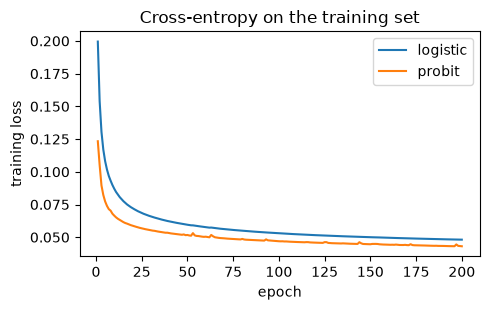

,model,test accuracy,correct / 114
0,sklearn LogisticRegression (baseline),0.9825,112
1,SGD logistic (PyTorch),0.9737,111
2,SGD probit (PyTorch),0.9825,112


In [8]:
std_normal = torch.distributions.Normal(0.0, 1.0)

def probit_model(X, w, b):
    return std_normal.cdf(X @ w + b)

w_pro, b_pro, hist_pro = train_sgd(probit_model, bce_loss, Xc_tr_t, yc_tr_t,
                                   lr=0.1, epochs=200, batch_size=32)
acc_probit = accuracy(probit_model, w_pro, b_pro, Xc_te_t, yc_te_t)
print(f"SGD probit regression: final training loss = {hist_pro[-1]:.4f}, "
      f"test accuracy = {acc_probit:.4f} ({int(round(acc_probit * len(yc_te)))}/{len(yc_te)})")

plot_history({"logistic": hist_log, "probit": hist_pro}, "Cross-entropy on the training set")

clf_table = pd.DataFrame({
    "model": ["sklearn LogisticRegression (baseline)", "SGD logistic (PyTorch)", "SGD probit (PyTorch)"],
    "test accuracy": [acc_baseline, acc_logistic, acc_probit]})
clf_table["correct / 114"] = (clf_table["test accuracy"] * len(yc_te)).round().astype(int)
clf_table.round(4)

In [9]:
unregularized_clf = LogisticRegression(C=np.inf, max_iter=5000).fit(Xc_tr_s, yc_tr)
correct_unregularized = (unregularized_clf.predict(Xc_te_s) == yc_te).sum()
print(f"Unregularized sklearn logistic: {correct_unregularized}/{len(yc_te)} correct")

Unregularized sklearn logistic: 105/114 correct


The SGD logistic model correctly classifies 111 of 114 test observations, giving accuracy 0.9737. The baseline and probit model each classify 112 correctly, giving accuracy 0.9825. Thus probit matches the baseline on this split, while SGD logistic makes one more error.

Removing the baseline's $\ell_2$ penalty lowers its accuracy to 105/114 on the same split. My SGD model is unregularized, but stops after 200 epochs rather than fully minimizing cross-entropy. Finite training can act as implicit regularization, which helps explain why its test accuracy is closer to the regularized baseline.

## Regression: ALE dataset

I use the same four predictors as in Problem 4 and an 80/20 split, giving 85 training observations and 22 test observations. The feature scaler is fitted on the training data. I compare both SGD models with scikit-learn's `LinearRegression` using test mean absolute error (MAE).

In [10]:
from sklearn.metrics import mean_absolute_error

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_ale, y_ale, test_size=0.2, random_state=42)
scaler_r = StandardScaler().fit(Xr_tr)
Xr_tr_s, Xr_te_s = scaler_r.transform(Xr_tr), scaler_r.transform(Xr_te)
print(f"train {Xr_tr.shape}, test {Xr_te.shape}")

ols = LinearRegression().fit(Xr_tr_s, yr_tr)
mae_baseline = mean_absolute_error(yr_te, ols.predict(Xr_te_s))
print(f"baseline sklearn LinearRegression: test MAE = {mae_baseline:.4f}")

Xr_tr_t, Xr_te_t = torch.tensor(Xr_tr_s), torch.tensor(Xr_te_s)
yr_tr_t, yr_te_t = torch.tensor(yr_tr), torch.tensor(yr_te)

train (85, 4), test (22, 4)
baseline sklearn LinearRegression: test MAE = 0.1954


### (a) Linear regression with squared-error loss

The model is $f(x_i)=w^\top x_i+b$. I minimize the mini-batch average of $(y_i-f(x_i))^2$ with SGD.

In [11]:
def linear_model(X, w, b):
    return X @ w + b

def mse_loss(pred, y):
    return ((y - pred) ** 2).mean()

def test_mae(w, b):
    with torch.no_grad():
        return (linear_model(Xr_te_t, w, b) - yr_te_t).abs().mean().item()

w_mse, b_mse, hist_mse = train_sgd(linear_model, mse_loss, Xr_tr_t, yr_tr_t,
                                   lr=0.01, epochs=1000, batch_size=16)
mae_mse = test_mae(w_mse, b_mse)
print(f"SGD linear regression (MSE): final training MSE = {hist_mse[-1]:.5f}, test MAE = {mae_mse:.4f}")

SGD linear regression (MSE): final training MSE = 0.05063, test MAE = 0.1963


### (b) Linear regression with a Student-$t$ loss

I use the same linear model with the negative log-likelihood of a Student-$t$ residual. With the specified $\nu=5$ and unit scale, the loss is

$$
L(y_i,f(x_i))=-\log\frac{\Gamma(3)}{\sqrt{5\pi}\,\Gamma(5/2)}
+3\log\left(1+\frac{(y_i-f(x_i))^2}{5}\right).
$$

I compute it with `torch.distributions.StudentT(df=5).log_prob`. The logarithmic growth makes large residuals contribute less to the loss than under squared error.

SGD linear regression (Student-t, nu=5): final training NLL = 0.99767, test MAE = 0.1948


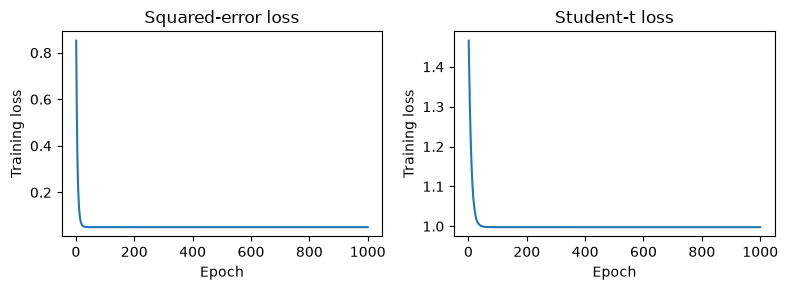

,model,test MAE
0,sklearn LinearRegression (baseline),0.1954
1,"SGD, squared error (PyTorch)",0.1963
2,"SGD, Student-t NLL, nu = 5 (PyTorch)",0.1948


In [12]:
student_t = torch.distributions.StudentT(df=5.0)

def student_t_nll(pred, y):
    return -student_t.log_prob(y - pred).mean()

w_t, b_t, hist_t = train_sgd(linear_model, student_t_nll, Xr_tr_t, yr_tr_t,
                             lr=0.01, epochs=1000, batch_size=16)
mae_t = test_mae(w_t, b_t)
print(f"SGD linear regression (Student-t, nu=5): final training NLL = {hist_t[-1]:.5f}, test MAE = {mae_t:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, h, title in zip(axes, [hist_mse, hist_t], ["Squared-error loss", "Student-t loss"]):
    ax.plot(np.arange(1, len(h) + 1), h)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training loss")
fig.tight_layout()
plt.show()

reg_table = pd.DataFrame({
    "model": ["sklearn LinearRegression (baseline)", "SGD, squared error (PyTorch)", "SGD, Student-t NLL, nu = 5 (PyTorch)"],
    "test MAE": [mae_baseline, mae_mse, mae_t]})
reg_table.round(4)

In [13]:
r_t = yr_tr - (Xr_tr_s @ w_t.numpy() + b_t.item())
quadratic_term = 0.6 * r_t ** 2
relative_gap = np.divide(
    quadratic_term - 3 * np.log1p(r_t ** 2 / 5), quadratic_term,
    out=np.zeros_like(r_t), where=quadratic_term > 0)
print(f"Training residual RMSE: {np.sqrt(np.mean(r_t ** 2)):.3f}")
print(f"Within 2% of quadratic: {(relative_gap <= 0.02).sum()}/{len(r_t)} residuals")
print(f"Largest absolute residual: {np.abs(r_t).max():.3f}; "
      f"largest relative difference: {relative_gap.max():.1%}")

Training residual RMSE: 0.225
Within 2% of quadratic: 82/85 residuals
Largest absolute residual: 1.144; largest relative difference: 11.2%


The baseline test MAE is 0.1954. SGD with squared-error loss gives 0.1963, and the Student-$t$ loss gives 0.1948. The Student-$t$ model improves on the baseline by only about 0.0006.

This small difference is consistent with the unit-scale Student-$t$ loss being close to quadratic over most observed residuals. Writing $r=y-f(x)$, its residual-dependent term is

$$
3\log(1+r^2/5)=0.6r^2-0.06r^4+O(r^6).
$$

At $r=0.2$, the quadratic approximation differs by only about 0.4%. For the fitted Student-$t$ model, it is within 2% for 82 of the 85 training residuals. The largest residual is 1.144, where the difference is 11.2%. Thus some downweighting occurs for the largest errors, but most observations contribute almost a rescaled squared-error loss. This helps explain why the fitted model has nearly the same test MAE as OLS.